# Experiment No. 6 (Computer Laboratory – I BE AI&DS)

**Aim:**  
Build a Tic-Tac-Toe game using reinforcement learning in Python by using the following tasks:  
a. Setting up the environment  
b. Defining the Tic-Tac-Toe game  
c. Building the reinforcement learning model  
d. Training the model  
e. Testing the model  

**Objectives:**  
1. Setup environment libraries and configure Q-learning hyperparameters (learning rate, discount factor, exploration rate).
2. Define the Tic-Tac-Toe game environment with board representation, state transitions, win detection, and reward design.
3. Implement the tabular Q-Learning agent with an epsilon-greedy policy and Bellman update formula.
4. Train the agent over 10,000 episodes and track the win rate progression.
5. Test and evaluate the trained agent over 1,000 games and demonstrate step-by-step game simulation.

In [1]:
# Cell 1 - Task a: Setting up the Environment
import numpy as np
import random
import matplotlib.pyplot as plt

# Hyperparameters for Reinforcement Learning
ALPHA = 0.2        # Learning rate (step size for Q-value updates)
GAMMA = 0.9        # Discount factor (importance of future rewards)
EPSILON = 0.3      # Exploration rate (epsilon-greedy policy)
EPISODES = 10000   # Total number of training games

print("Environment setup completed!")
print(f"Hyperparameters -> Alpha: {ALPHA}, Gamma: {GAMMA}, Epsilon: {EPSILON}, Episodes: {EPISODES}")

Environment setup completed!
Hyperparameters -> Alpha: 0.2, Gamma: 0.9, Epsilon: 0.3, Episodes: 10000


In [2]:
# Cell 2 - Task b: Defining the Tic-Tac-Toe Game Environment
class TicTacToe:
    def __init__(self):
        # Board: 1D array of 9 cells (0: empty, 1: Player X / Agent, -1: Player O / Opponent)
        self.board = np.zeros(9, dtype=int)

    def reset(self):
        self.board = np.zeros(9, dtype=int)
        return tuple(self.board)

    def available_actions(self):
        return [i for i in range(9) if self.board[i] == 0]

    def check_winner(self):
        # 8 winning lines: 3 rows, 3 columns, 2 diagonals
        winning_lines = [
            (0, 1, 2), (3, 4, 5), (6, 7, 8),  # Rows
            (0, 3, 6), (1, 4, 7), (2, 5, 8),  # Columns
            (0, 4, 8), (2, 4, 6)             # Diagonals
        ]
        for a, b, c in winning_lines:
            if self.board[a] != 0 and self.board[a] == self.board[b] == self.board[c]:
                return self.board[a]  # Returns 1 (Agent wins) or -1 (Opponent wins)
        if 0 not in self.board:
            return 0  # Draw
        return None   # Game continues

    def step(self, action, player):
        self.board[action] = player
        winner = self.check_winner()
        done = (winner is not None)

        # Reward scheme
        if winner == 1:
            reward = 1.0    # Win reward
        elif winner == -1:
            reward = -1.0   # Loss penalty
        elif winner == 0:
            reward = 0.5    # Draw reward
        else:
            reward = 0.0    # Ongoing move

        return tuple(self.board), reward, done

    def display(self):
        symbols = {0: ' ', 1: 'X', -1: 'O'}
        print("-------------")
        for r in range(3):
            print(f"| {symbols[self.board[r*3]]} | {symbols[self.board[r*3+1]]} | {symbols[self.board[r*3+2]]} |")
            print("-------------")

In [3]:
# Cell 3 - Task c: Building the Reinforcement Learning Model (Q-Learning Agent)
class QLearningAgent:
    def __init__(self, alpha=ALPHA, gamma=GAMMA, epsilon=EPSILON):
        self.q_table = {}  # Q-table: maps (state_tuple, action) -> Q-value
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon

    def get_q_value(self, state, action):
        return self.q_table.get((state, action), 0.0)

    def choose_action(self, state, available_actions):
        if not available_actions:
            return None
        # Epsilon-Greedy policy: Exploration vs Exploitation
        if random.random() < self.epsilon:
            return random.choice(available_actions)  # Explore random action

        # Exploit: Choose action with maximum Q-value
        q_values = [self.get_q_value(state, a) for a in available_actions]
        max_q = max(q_values)
        best_actions = [a for a, q in zip(available_actions, q_values) if q == max_q]
        return random.choice(best_actions)

    def update_q_value(self, state, action, reward, next_state, next_available_actions, done):
        current_q = self.get_q_value(state, action)
        if done:
            target = reward
        else:
            max_next_q = max([self.get_q_value(next_state, a) for a in next_available_actions]) if next_available_actions else 0.0
            target = reward + self.gamma * max_next_q
        # Q-Learning update rule (Bellman equation)
        self.q_table[(state, action)] = current_q + self.alpha * (target - current_q)

Training Q-Learning Agent over 10000 games...
Training complete! Total learned state-action pairs in Q-Table: 4409


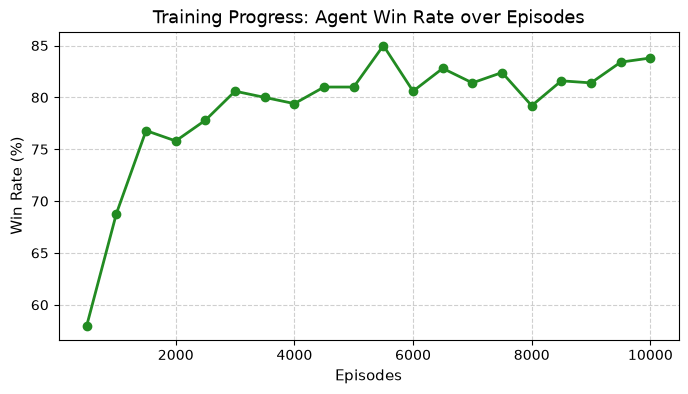

In [4]:
# Cell 4 - Task d: Training the Model
env = TicTacToe()
agent = QLearningAgent()

win_history = []
window_wins = 0

print(f"Training Q-Learning Agent over {EPISODES} games...")

for episode in range(1, EPISODES + 1):
    state = env.reset()
    done = False

    while not done:
        # Agent move (Player 1 / 'X')
        action = agent.choose_action(state, env.available_actions())
        next_state, reward, done = env.step(action, player=1)

        if done:
            agent.update_q_value(state, action, reward, next_state, [], done)
            if reward == 1.0:
                window_wins += 1
            break

        # Opponent move (Random player / Player -1 / 'O')
        opp_action = random.choice(env.available_actions())
        opp_next_state, opp_reward, done = env.step(opp_action, player=-1)

        if done:
            # If opponent won, assign negative reward to agent
            agent_reward = -1.0 if opp_reward == -1.0 else 0.5
            agent.update_q_value(state, action, agent_reward, opp_next_state, [], done)
            break

        # Intermediate state update
        agent.update_q_value(state, action, 0.0, opp_next_state, env.available_actions(), False)
        state = opp_next_state

    # Track win rate per 500 episodes
    if episode % 500 == 0:
        win_rate = (window_wins / 500) * 100
        win_history.append(win_rate)
        window_wins = 0

print(f"Training complete! Total learned state-action pairs in Q-Table: {len(agent.q_table)}")

# Plot Win Rate progression over training episodes
plt.figure(figsize=(8, 4))
plt.plot(range(500, EPISODES + 1, 500), win_history, marker='o', color='forestgreen', linewidth=2)
plt.title("Training Progress: Agent Win Rate over Episodes", fontsize=13)
plt.xlabel("Episodes", fontsize=11)
plt.ylabel("Win Rate (%)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [5]:
# Cell 5 - Task e: Testing the Model
# Set epsilon to 0 (pure exploitation: no random moves during testing)
agent.epsilon = 0.0
TEST_GAMES = 1000

wins, draws, losses = 0, 0, 0

for _ in range(TEST_GAMES):
    state = env.reset()
    done = False

    while not done:
        # Trained agent move
        action = agent.choose_action(state, env.available_actions())
        state, reward, done = env.step(action, player=1)
        if done:
            if reward == 1.0:
                wins += 1
            elif reward == 0.5:
                draws += 1
            break

        # Opponent move (Random player)
        opp_action = random.choice(env.available_actions())
        state, opp_reward, done = env.step(opp_action, player=-1)
        if done:
            if opp_reward == -1.0:
                losses += 1
            elif opp_reward == 0.5:
                draws += 1
            break

print("=" * 45)
print(f"      TEST EVALUATION ({TEST_GAMES} Games)")
print("=" * 45)
print(f"Agent Wins  : {wins:4d} ({wins/TEST_GAMES*100:.1f}%)")
print(f"Draws       : {draws:4d} ({draws/TEST_GAMES*100:.1f}%)")
print(f"Agent Losses: {losses:4d} ({losses/TEST_GAMES*100:.1f}%)")
print("=" * 45)

# Demonstrate a Step-by-Step Sample Game Simulation
print("\n--- Sample Game Simulation (Agent 'X' vs Random 'O') ---")
sample_state = env.reset()
env.display()

move = 1
while True:
    # Agent turn
    act = agent.choose_action(sample_state, env.available_actions())
    sample_state, r, end = env.step(act, player=1)
    print(f"\nMove {move}: Agent 'X' plays at position {act}")
    env.display()
    if end:
        print("Result:", "Agent 'X' Wins!" if r == 1.0 else "Draw!")
        break

    # Opponent turn
    opp_act = random.choice(env.available_actions())
    sample_state, r, end = env.step(opp_act, player=-1)
    print(f"\nMove {move+1}: Opponent 'O' plays at position {opp_act}")
    env.display()
    if end:
        print("Result:", "Opponent 'O' Wins!" if r == -1.0 else "Draw!")
        break
    move += 2

      TEST EVALUATION (1000 Games)
Agent Wins  :  973 (97.3%)
Draws       :   25 (2.5%)
Agent Losses:    2 (0.2%)

--- Sample Game Simulation (Agent 'X' vs Random 'O') ---
-------------
|   |   |   |
-------------
|   |   |   |
-------------
|   |   |   |
-------------

Move 1: Agent 'X' plays at position 1
-------------
|   | X |   |
-------------
|   |   |   |
-------------
|   |   |   |
-------------

Move 2: Opponent 'O' plays at position 6
-------------
|   | X |   |
-------------
|   |   |   |
-------------
| O |   |   |
-------------

Move 3: Agent 'X' plays at position 4
-------------
|   | X |   |
-------------
|   | X |   |
-------------
| O |   |   |
-------------

Move 4: Opponent 'O' plays at position 5
-------------
|   | X |   |
-------------
|   | X | O |
-------------
| O |   |   |
-------------

Move 5: Agent 'X' plays at position 8
-------------
|   | X |   |
-------------
|   | X | O |
-------------
| O |   | X |
-------------

Move 6: Opponent 'O' plays at position